# 8. Barotropic model

The barotropic model is the single-level, non-divergent reduction of the LBM: it
keeps only the vorticity equation on one layer and drops divergence, temperature
and humidity. It is the cheapest setting for the diagnostics of this guide — a
steady Rossby-wave response, a modal instability, and an optimal-growth analysis
— because its operator acts on vorticity coefficients alone, so each zonal
wavenumber is a matrix of only $N-m+1$ entries. Crucially, having **no gravity
waves** it has a clean enstrophy/energy norm, which makes the singular-vector
(optimal-growth) analysis of WK guide §5.3 unambiguous here, unlike in the full
primitive-equation operator ([](05-modal-decomposition.ipynb)).

The linearised barotropic vorticity equation about a zonal flow $\bar u(\phi)$ is

$$\frac{\partial \zeta'}{\partial t}
 = -\nabla\!\cdot\!\big[\mathbf{v}'(\bar\zeta+f)+\bar{\mathbf v}\zeta'\big]
   - r\,\zeta' - \nu\nabla^4\zeta',
\qquad \mathbf{v}'=\mathbf{k}\times\nabla\psi',\ \zeta'=\nabla^2\psi',$$

implemented in `lbmtools.Barotropic` directly on the guide's transforms.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "4")
root = os.path.abspath("")
while root != os.path.dirname(root) and not os.path.isdir(os.path.join(root, "pylbm_isca")):
    root = os.path.dirname(root)
sys.path.insert(0, root)
sys.path.insert(0, os.path.join(root, "docs", "book"))
import numpy as np
import matplotlib.pyplot as plt
from pylbm_isca import Config, LBM, Spectral, VerticalGrid
from pylbm_isca.backend import asnumpy, gpu_available
import lbmtools as lt

DEVICE = "gpu" if gpu_available() else "cpu"
sp = Spectral(nlon=64, nlat=32, nmax=21, device=DEVICE)   # T21 L20, runs offline
vg = VerticalGrid(device=DEVICE)
lon, lat, sig = sp.lon_deg, sp.lat_deg, asnumpy(vg.sig)
print(f"PyLBM-Isca  T{sp.nmax}  {sp.nlon}x{sp.nlat}  L{vg.kmax}  backend={DEVICE}")

PyLBM-Isca  T21  64x32  L20  backend=gpu


## 8.1 Steady response — a stationary Rossby wave

On a solid-body super-rotation ($\bar u=15\cos\phi$) a localised vorticity
source radiates a stationary Rossby-wave train — the barotropic analogue of
§3.1. We solve $\mathbf{A}_m\,\zeta_m=-S_m$ wavenumber by wavenumber and sum.

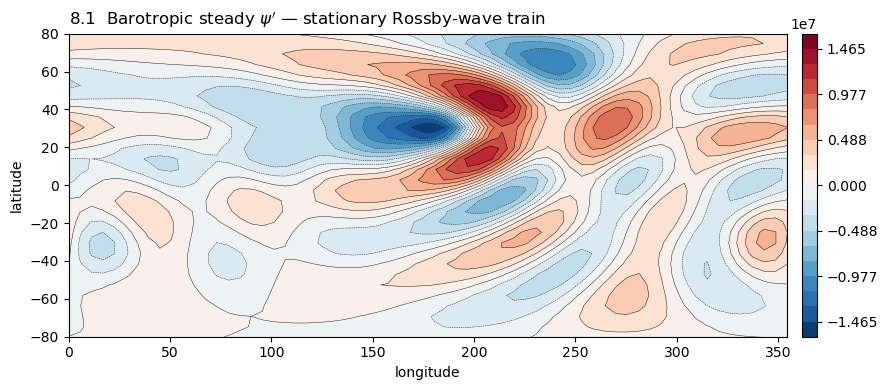

In [2]:
coslat = np.sqrt(1 - asnumpy(sp.mu)**2)
ubar = 15.0*coslat[:, None]*np.ones((sp.nlat, sp.nlon))
bar = lt.Barotropic(sp, ubar, drag_days=10.0)

dl = (lon[None, :]-180+180) % 360 - 180                 # vorticity source at 30N
S_g = 3e-10*np.exp(-(dl/12.0)**2 - ((lat[:, None]-30.0)/8.0)**2)
S_s = asnumpy(sp.grid_to_wave(S_g))

zeta = np.zeros((sp.nmax+1, sp.nmax+1), complex)
for m in range(1, sp.nmax+1):
    A, ns = bar.block(m)
    zeta[m, ns] = np.linalg.solve(A, -S_s[m, ns])
psi = bar.psi_grid(sp.xp.asarray(zeta))

v = np.abs(psi).max() or 1.0
fig, ax = plt.subplots(figsize=(9, 4))
cf = ax.contourf(lon, lat, psi, levels=np.linspace(-v, v, 21), cmap="RdBu_r")
ax.contour(lon, lat, psi, levels=np.linspace(-v, v, 21), colors="k", linewidths=0.3)
ax.set_ylim(-80, 80); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title(r"8.1  Barotropic steady $\psi'$ — stationary Rossby-wave train",
             loc="left")
fig.colorbar(cf, ax=ax, pad=0.02, fraction=0.025); fig.tight_layout(); plt.show()

## 8.2 Modal decomposition — barotropic instability

A sharp **Bickley jet** $\bar u=U\,\mathrm{sech}^2[(\phi-\phi_0)/\delta]$
reverses the meridional PV gradient and is **barotropically unstable**
(Rayleigh–Kuo). Diagonalising each $\mathbf{A}_m$ gives the full spectrum; the
growth peaks at an intermediate wavenumber — the classic instability curve.

In [3]:
phi = np.deg2rad(lat)
U, phi0, delta = 60.0, np.deg2rad(45.0), np.deg2rad(7.0)
ujet = U/np.cosh((phi-phi0)/delta)**2
barj = lt.Barotropic(sp, ujet[:, None]*np.ones((sp.nlat, sp.nlon)),
                     drag_days=1e6, nu4=5e15)            # ~inviscid

ms = np.arange(1, 13); gmax, modes = [], {}
for m in ms:
    A, ns = barj.block(m)
    w, V = np.linalg.eig(A)
    j = int(np.argmax(w.real)); gmax.append(w[j].real*86400.0)
    modes[m] = (ns, V[:, j], A)
mbest = int(ms[int(np.argmax(gmax))])
print(f"most unstable wavenumber m={mbest}, growth {max(gmax):.3f} /day")

most unstable wavenumber m=5, growth 0.877 /day


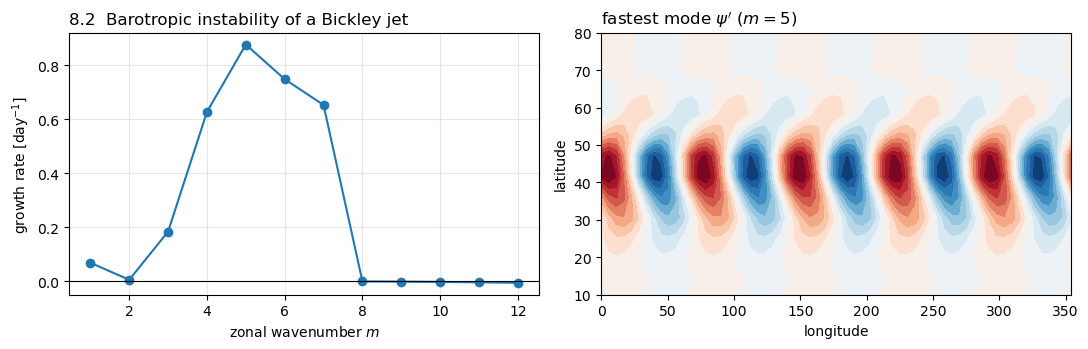

Growth vanishes at m=1 and high m, peaking in between — the Rayleigh-Kuo barotropic-instability signature.


In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(ms, gmax, "o-"); a1.axhline(0, color="k", lw=0.8)
a1.set_xlabel("zonal wavenumber $m$"); a1.set_ylabel("growth rate [day$^{-1}$]")
a1.set_title("8.2  Barotropic instability of a Bickley jet", loc="left")
a1.grid(alpha=0.3)
ns, vec, _ = modes[mbest]
z = np.zeros((sp.nmax+1, sp.nmax+1), complex); z[mbest, ns] = vec
pm = bar.psi_grid(sp.xp.asarray(z)); v = np.abs(pm).max() or 1.0
a2.contourf(lon, lat, pm, levels=np.linspace(-v, v, 19), cmap="RdBu_r")
a2.set_ylim(10, 80); a2.set_xlabel("longitude"); a2.set_ylabel("latitude")
a2.set_title(f"fastest mode $\\psi'$ ($m={mbest}$)", loc="left")
fig.tight_layout(); plt.show()
print("Growth vanishes at m=1 and high m, peaking in between — the Rayleigh-Kuo "
      "barotropic-instability signature.")

## 8.3 Singular vectors — optimal growth

Eigenmodes describe $t\to\infty$. Over a **finite** time $\tau$ a non-normal
operator can amplify a disturbance far more than any eigenmode grows (Farrell
1988). The optimal patterns are the singular vectors of the propagator
$\mathbf{M}(\tau)=e^{\mathbf{A}_m\tau}$ **in the energy norm** — here the
streamfunction (kinetic) energy, a well-defined inner product because there are
no gravity waves. We form $\mathbf{M}$ by `scipy.linalg.expm` and take the SVD
of the energy-weighted propagator.

In [5]:
from scipy.linalg import expm
from numpy.linalg import svd, eigvals
m = mbest
A, ns = barj.block(m)
il = np.abs(asnumpy(sp.inv_laplace)[ns])                # sqrt energy weight: |psi|~|il*zeta|
tau = 2.0
M = expm(A*tau*86400.0)
G = il[:, None]*M*(1.0/il)[None, :]                     # energy-normalised propagator
Usv, S, Vh = svd(G)
g1 = eigvals(A).real.max()*86400.0
print(f"m={m}: optimal energy amplification over {tau:.0f} d: "
      f"sigma1^2 = {S[0]**2:.1f}")
print(f"fastest eigenmode over the same time: e^(2*lambda*tau) = "
      f"{np.exp(2*g1*tau/86400*86400):.1f}")

m=5: optimal energy amplification over 2 d: sigma1^2 = 179.8
fastest eigenmode over the same time: e^(2*lambda*tau) = 33.4


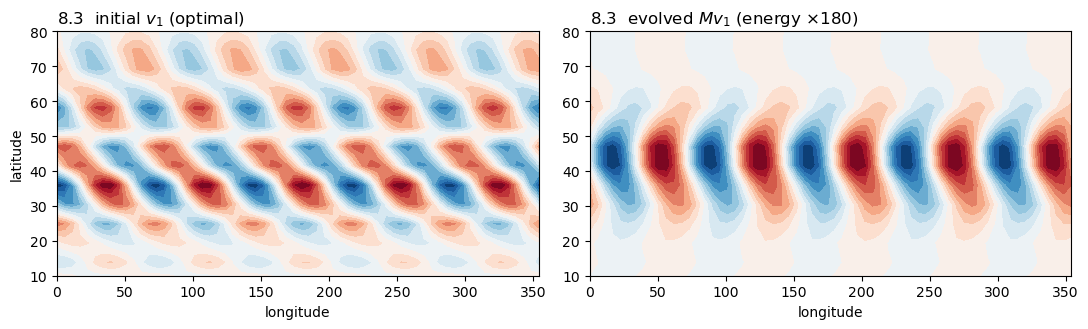

The optimal initial perturbation tilts against the shear and amplifies as it untilts — optimal (non-normal) growth, exceeding the eigenmode rate.


In [6]:
# initial optimal perturbation (right s.v.) and its evolved state M v1
v1 = (1.0/il)*Vh.conj()[0]                              # physical coeffs
ev1 = M @ v1
def psi_of(coef):
    z = np.zeros((sp.nmax+1, sp.nmax+1), complex); z[m, ns] = coef
    return bar.psi_grid(sp.xp.asarray(z))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, fld, ttl in ((axs[0], psi_of(v1), "initial $v_1$ (optimal)"),
                     (axs[1], psi_of(ev1), f"evolved $M v_1$ (energy $\\times{S[0]**2:.0f}$)")):
    v = np.abs(fld).max() or 1.0
    ax.contourf(lon, lat, fld, levels=np.linspace(-v, v, 19), cmap="RdBu_r")
    ax.set_ylim(10, 80); ax.set_title("8.3  "+ttl, loc="left")
    ax.set_xlabel("longitude")
axs[0].set_ylabel("latitude"); fig.tight_layout(); plt.show()
print("The optimal initial perturbation tilts against the shear and amplifies as "
      "it untilts — optimal (non-normal) growth, exceeding the eigenmode rate.")

### Summary

The barotropic model reproduces all three diagnostics of the full LBM in the
cheapest, cleanest setting: a **steady stationary-wave response** (§8.1), a
**modal instability** (§8.2), and **optimal transient growth** (§8.3). Because
the operator is one layer of vorticity with no gravity waves, every zonal
wavenumber block is tiny, the full spectrum is immediate, and the energy norm is
unambiguous — which is why the barotropic model is the standard first stop for
Rossby-wave propagation, instability and optimal-perturbation studies.